
🪙 RUNNING: ETHUSDT | 1h | 01/01/2024 -> 05/03/2026
⏳ Downloading ETHUSDT 1h...
🚀 Running strategy...

🎯 Strategy_1_52_191 + KC filters (Python port) | 3 RSI slopes + KC50/49 filter + PendingStop + ATR SL/TP + Expire + Fees
     Final Equity: 16096.0173
     Total Return: 0.6096
    CAGR (approx): 0.2455
     Max Drawdown: -0.1068
           Sharpe: 1.5101
           Trades: 183
          Winrate: 0.5738
    Avg PnL/Trade: 33.3116
    Profit Factor: 1.3849


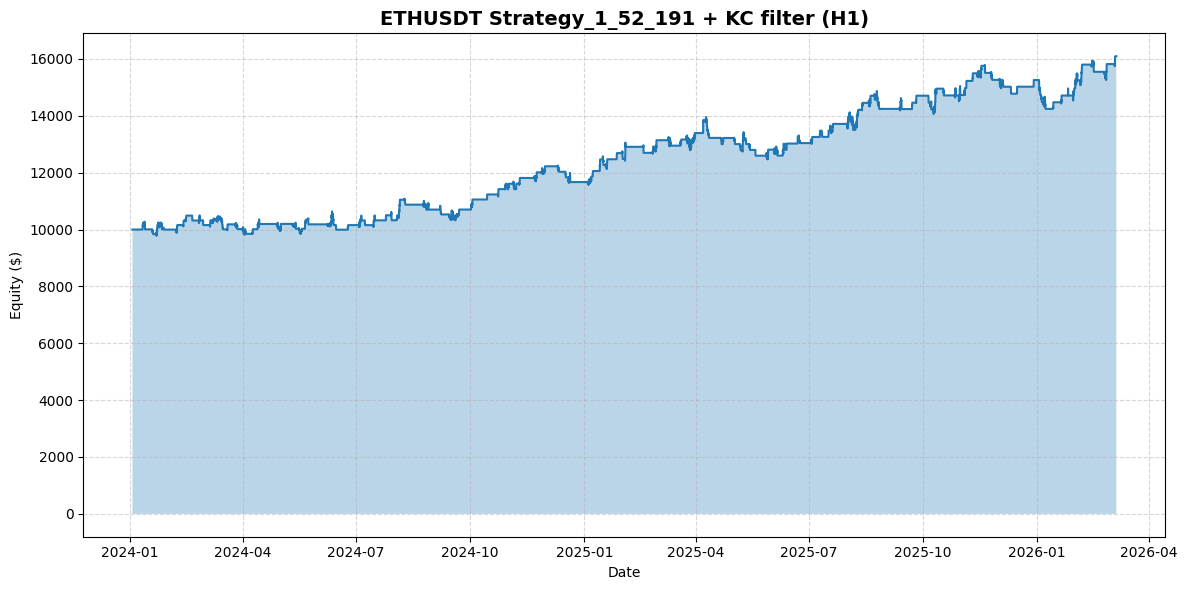


📈 Exit Reasons:
Reason
TakeProfit    105
StopLoss       78
Name: count, dtype: int64


In [8]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# =========================================================
# 1) FETCH BINANCE DATA
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {symbol} {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200:
                print("Error:", r.status_code, r.text)
                break

            data = r.json()
            if not data:
                break

            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)

        except Exception as e:
            print("Fetch error:", e)
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) INDICATORS (ATR Wilder, RSI Wilder, WeightedClose, Keltner 50/49)
# =========================================================
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # Price variants
    data["MEDIAN"] = (data["High"] + data["Low"]) / 2.0
    data["WEIGHTED_CLOSE"] = (data["High"] + data["Low"] + 2.0 * data["Close"]) / 4.0

    # True Range
    prev_close = data["Close"].shift(1)
    tr = pd.concat([
        (data["High"] - data["Low"]),
        (data["High"] - prev_close).abs(),
        (data["Low"] - prev_close).abs(),
    ], axis=1).max(axis=1)
    data["TR"] = tr

    # Wilder ATR (RMA)
    def atr_wilder(tr_series: pd.Series, period: int) -> pd.Series:
        return tr_series.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = atr_wilder(data["TR"], 20)
    data["ATR_25"] = atr_wilder(data["TR"], 25)
    data["ATR_40"] = atr_wilder(data["TR"], 40)

    # Wilder RSI (RMA)
    def rsi_wilder(series: pd.Series, period: int) -> pd.Series:
        delta = series.diff()
        gain = delta.clip(lower=0.0)
        loss = (-delta).clip(lower=0.0)
        avg_gain = gain.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
        avg_loss = loss.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
        rs = avg_gain / avg_loss
        return 100 - (100 / (1 + rs))

    # 3 RSI theo strategy 1.52.191
    data["RSI_14_Close"] = rsi_wilder(data["Close"], 14)
    data["RSI_50_Median"] = rsi_wilder(data["MEDIAN"], 50)
    data["RSI_30_Open"] = rsi_wilder(data["Open"], 30)

    # Highest/Lowest WEIGHTED_CLOSE lookback=14
    data["HH_WC_14"] = data["WEIGHTED_CLOSE"].rolling(14).max()
    data["LL_WC_14"] = data["WEIGHTED_CLOSE"].rolling(14).min()

    # ===== NEW: Keltner Channel 50 (2.4) and 49 (1.5) =====
    # mapping: EMA(Close, n) +/- mult * ATR(n)
    def keltner(df_: pd.DataFrame, period: int, mult: float, atr_period: int = None):
        if atr_period is None:
            atr_period = period
        mid = df_["Close"].ewm(span=period, adjust=False).mean()
        atrp = atr_wilder(df_["TR"], atr_period)
        up = mid + mult * atrp
        lo = mid - mult * atrp
        return up, lo

    data["KC50_UP_2p4"], data["KC50_LO_2p4"] = keltner(data, period=50, mult=2.4, atr_period=50)
    data["KC49_UP_1p5"], data["KC49_LO_1p5"] = keltner(data, period=49, mult=1.5, atr_period=49)

    data.dropna(inplace=True)
    return data


# =========================================================
# 3) BACKTESTER (3 RSI + Keltner filter + Pending Stop + Expiration + SL/TP + Fees)
# =========================================================
class SQ152191_WithKC_Backtester:
    """
    Base Strategy_1_52_191 + NEW Keltner filter:

    Long signal:
      RSI_14_Close(shift=4)   < RSI_14_Close(shift=3)
      RSI_50_Median(shift=2)  < RSI_50_Median(shift=1)
      RSI_30_Open(shift=4)    < RSI_30_Open(shift=3)
      Open(0) > KC50_UP_2p4(shift=1)
      Open(0) > KC49_UP_1p5(shift=1)

    Short signal:
      RSI_14_Close(shift=4)   > RSI_14_Close(shift=3)
      RSI_50_Median(shift=2)  > RSI_50_Median(shift=1)
      RSI_30_Open(shift=4)    > RSI_30_Open(shift=3)
      Open(0) < KC50_LO_2p4(shift=1)
      Open(0) < KC49_LO_1p5(shift=1)

    Entry:
      BUYSTOP  = HH_WC_14(shift=2) + 2.4*ATR_40(shift=1)
      SELLSTOP = LL_WC_14(shift=2) - 2.4*ATR_40(shift=1)

    Expire: 5 bars
    SLdist = 2.6*ATR_20(shift=1)
    TPdist = 3.0*ATR_25(shift=1)
    """
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.position = None  # "LONG"/"SHORT"/None
        self.entry_price = 0.0
        self.entry_idx = 0
        self.qty = 0.0
        self.sl = 0.0
        self.tp = 0.0

        self.pending = None

        self.trades = []
        self.equity_curve = []

        # params
        self.price_entry_mult = 2.4
        self.pending_expiration = 5
        self.sl_coef = 2.6
        self.tp_coef = 3.2
        self.risk_pct = 0.015

        # fees
        self.fee_rate = 0.001
        self._last_entry_fee = 0.0

    def run(self):
        idxs = self.df.index
        n = len(self.df)

        for i in range(n):
            t = idxs[i]
            bar = self.df.iloc[i]

            # A) Manage open position: SL/TP only
            if self.position is not None:
                if self.position == "LONG":
                    if bar["Low"] <= self.sl:
                        self.close_position(self.sl, t, "StopLoss")
                        self.append_equity(t)
                        continue
                    if bar["High"] >= self.tp:
                        self.close_position(self.tp, t, "TakeProfit")
                        self.append_equity(t)
                        continue
                else:  # SHORT
                    if bar["High"] >= self.sl:
                        self.close_position(self.sl, t, "StopLoss")
                        self.append_equity(t)
                        continue
                    if bar["Low"] <= self.tp:
                        self.close_position(self.tp, t, "TakeProfit")
                        self.append_equity(t)
                        continue

            # B) Manage pending
            if self.position is None and self.pending is not None:
                if i >= self.pending["expire_idx"]:
                    self.pending = None
                else:
                    p = self.pending["price"]
                    if self.pending["type"] == "BUY_STOP":
                        if bar["High"] >= p:
                            fill = max(p, bar["Open"])
                            self.open_position("LONG", fill, i,
                                               sl_dist=self.pending["sl_dist"],
                                               tp_dist=self.pending["tp_dist"])
                            self.pending = None
                    elif self.pending["type"] == "SELL_STOP":
                        if bar["Low"] <= p:
                            fill = min(p, bar["Open"])
                            self.open_position("SHORT", fill, i,
                                               sl_dist=self.pending["sl_dist"],
                                               tp_dist=self.pending["tp_dist"])
                            self.pending = None

            # C) Signals -> place pending
            if self.position is None and self.pending is None:
                # Need history for shift=4/3, 2/1, and Keltner shift=1, plus entry shift=2
                if i < 6:
                    self.append_equity(t)
                    continue

                open_0 = bar["Open"]

                # RSI conditions
                rsiC_4 = self.df.iloc[i-4]["RSI_14_Close"]
                rsiC_3 = self.df.iloc[i-3]["RSI_14_Close"]

                rsiM_2 = self.df.iloc[i-2]["RSI_50_Median"]
                rsiM_1 = self.df.iloc[i-1]["RSI_50_Median"]

                rsiO_4 = self.df.iloc[i-4]["RSI_30_Open"]
                rsiO_3 = self.df.iloc[i-3]["RSI_30_Open"]

                # NEW KC filters shift=1
                kc50_up_1 = self.df.iloc[i-1]["KC50_UP_2p4"]
                kc50_lo_1 = self.df.iloc[i-1]["KC50_LO_2p4"]
                kc49_up_1 = self.df.iloc[i-1]["KC49_UP_1p5"]
                kc49_lo_1 = self.df.iloc[i-1]["KC49_LO_1p5"]

                long_signal = (
                    (rsiC_4 < rsiC_3) and (rsiM_2 < rsiM_1) and (rsiO_4 < rsiO_3)
                    and (open_0 > kc50_up_1) and (open_0 > kc49_up_1)
                )
                short_signal = (
                    (rsiC_4 > rsiC_3) and (rsiM_2 > rsiM_1) and (rsiO_4 > rsiO_3)
                    and (open_0 < kc50_lo_1) and (open_0 < kc49_lo_1)
                )

                if not long_signal and not short_signal:
                    self.append_equity(t)
                    continue

                # Entry uses HH/LL weighted_close shift=2, ATR40 shift=1
                hh_wc_2 = self.df.iloc[i-2]["HH_WC_14"]
                ll_wc_2 = self.df.iloc[i-2]["LL_WC_14"]
                atr40_1 = self.df.iloc[i-1]["ATR_40"]

                # SL/TP distances use ATR20/ATR25 shift=1
                atr20_1 = self.df.iloc[i-1]["ATR_20"]
                atr25_1 = self.df.iloc[i-1]["ATR_25"]
                sl_dist = self.sl_coef * atr20_1
                tp_dist = self.tp_coef * atr25_1

                if long_signal:
                    entry = hh_wc_2 + self.price_entry_mult * atr40_1
                    self.pending = {
                        "type": "BUY_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }
                elif short_signal and (not long_signal):
                    entry = ll_wc_2 - self.price_entry_mult * atr40_1
                    self.pending = {
                        "type": "SELL_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }

            # D) Append equity
            self.append_equity(t)

    def append_equity(self, t):
        mtm = self.balance
        close_px = float(self.df.loc[t, "Close"])
        if self.position == "LONG":
            mtm += (close_px - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - close_px) * self.qty
        self.equity_curve.append({"time": t, "equity": mtm})

    def open_position(self, side: str, price: float, bar_idx: int, sl_dist: float, tp_dist: float):
        self.position = side
        self.entry_price = float(price)
        self.entry_idx = int(bar_idx)

        if side == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist

        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        self.qty = float((risk_amount / sl_distance) if sl_distance > 0 else 0.0)

        entry_fee = self.fee_rate * abs(self.entry_price * self.qty)
        self.balance -= entry_fee
        self._last_entry_fee = float(entry_fee)

    def close_position(self, price: float, t, reason: str):
        price = float(price)

        if self.position == "LONG":
            pnl_gross = (price - self.entry_price) * self.qty
        else:
            pnl_gross = (self.entry_price - price) * self.qty

        exit_fee = self.fee_rate * abs(price * self.qty)
        pnl_net = pnl_gross - exit_fee
        self.balance += pnl_net

        self.trades.append({
            "Exit Time": t,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "Qty": self.qty,
            "PnL_gross": pnl_gross,
            "EntryFee": self._last_entry_fee,
            "ExitFee": exit_fee,
            "TotalFee": self._last_entry_fee + exit_fee,
            "PnL_net": pnl_gross - (self._last_entry_fee + exit_fee),
            "Reason": reason,
            "Balance": self.balance
        })

        self.position = None
        self.entry_price = 0.0
        self.qty = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self._last_entry_fee = 0.0


# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data).set_index("time")
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = float(eq_df["equity"].iloc[-1])
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = float(dd.min())

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()
    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = float((mean_ret / std_ret) * np.sqrt(bars_per_year)) if std_ret and std_ret != 0 else 0.0

    pnl_col = "PnL_net"
    total_trades = int(len(trades_df))
    win_trades = int(len(trades_df[trades_df[pnl_col] > 0]))
    win_rate = (win_trades / total_trades) if total_trades > 0 else 0.0
    avg_pnl = float(trades_df[pnl_col].mean()) if total_trades > 0 else 0.0
    gross_profit = float(trades_df.loc[trades_df[pnl_col] > 0, pnl_col].sum())
    gross_loss = float(abs(trades_df.loc[trades_df[pnl_col] < 0, pnl_col].sum()))
    profit_factor = float((gross_profit / gross_loss)) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": float(total_return),
        "CAGR (approx)": float(cagr),
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": float(win_rate),
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol: str):
    print("\n" + "="*90)
    print("🎯 Strategy_1_52_191 + KC filters (Python port) | 3 RSI slopes + KC50/49 filter + PendingStop + ATR SL/TP + Expire + Fees")
    print("="*90)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*90)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3)
    plt.title(f"{symbol} Strategy_1_52_191 + KC filter (H1)", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "05/03/2026"

    symbol = "ETHUSDT"
    initial_balance = 10000.0
    min_bars = 900  # vì RSI50 + KC50 cần warmup

    print("\n" + "=" * 90)
    print(f"🪙 RUNNING: {symbol} | {interval} | {start_date} -> {end_date}")
    print("=" * 90)

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)
    if df_raw is None or df_raw.empty or len(df_raw) <= min_bars:
        print(f"❌ Insufficient data. Bars={0 if df_raw is None else len(df_raw)}")
        raise SystemExit

    df_calc = calculate_indicators(df_raw)

    print("🚀 Running strategy...")
    bt = SQ152191_WithKC_Backtester(df_calc, initial_balance=initial_balance)

    # Quick tune:
    # bt.fee_rate = 0.0006

    bt.run()

    trades_df = pd.DataFrame(bt.trades)
    if trades_df.empty:
        print("⚠️ No trades.")
        raise SystemExit

    metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
    print_report_and_plot(metrics, symbol)

    print("\n📈 Exit Reasons:")
    print(trades_df["Reason"].value_counts())